## Data Cleaning, Preprocessing and EDA



---
### Contents
1. Load and inspect
2. Handling missing data
3. Encoding categorical variables
4. Outlier removal
5. Normalization / scaling (leakage-safe train/test split)
6. Feature engineering (selection and dimension reduction)
7. Handling class imbalance in glucose risk classification
8. EDA visualizations
9. Saving the processed dataset

## Load And inspect 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

FIGDIR = "results/eda_visualizations"
import os; os.makedirs(FIGDIR, exist_ok=True)

In [2]:
ALL = pd.read_csv("results/outputs/diabetes_all_records.csv")
GLU = pd.read_csv("results/outputs/diabetes_glucose.csv")

print("all records:", ALL.shape)
print("glucose table:", GLU.shape)

all records: (29330, 19)
glucose table: (13511, 31)


In [3]:
ALL.measurement_type.value_counts()

measurement_type
insulin     14401
glucose     13650
meal          514
event         425
exercise      305
unknown        35
Name: count, dtype: int64

In [4]:

print(ALL.issue.value_counts())
print("\nclean rows:", ALL.is_clean.sum(), "of", len(ALL))

issue
bad_or_missing_date;bad_or_missing_time    33
undocumented_code;duplicate_record         22
glucose_out_of_range                       17
undocumented_code                          13
insulin_out_of_range                        9
duplicate_record                            7
bad_or_missing_date                         7
bad_or_missing_time                         5
Name: count, dtype: int64

clean rows: 29217 of 29330


In [5]:
ALL[~ALL.is_clean][["patient_id","raw_date","raw_time","raw_code","raw_value","issue"]].head(20)

,patient_id,raw_date,raw_time,raw_code,raw_value,issue
74,1,05-01-1991,17:23,34,163,insulin_out_of_range
1112,2,10-31-1989,12:00,60,0Hi,glucose_out_of_range
1146,2,11-04-1989,18:00,62,0Hi,glucose_out_of_range
1152,2,11-05-1989,12:00,60,0Hi,glucose_out_of_range
1160,2,11-06-1989,12:00,60,0Hi,glucose_out_of_range
1164,2,11-06-1989,22:00,48,0Hi,glucose_out_of_range
1178,2,11-08-1989,18:00,62,0Lo,glucose_out_of_range
1554,2,12-25-1989,22:00,48,0Hi,glucose_out_of_range
1779,3,07-30-1990,05:28,33,3,duplicate_record
1796,3,08-01-1990,16:28,65,0,duplicate_record


In [6]:
ALL[ALL.raw_value.astype(str).str.contains("Hi|Lo", na=False)][
    ["patient_id","raw_date","raw_code","raw_value"]]

,patient_id,raw_date,raw_code,raw_value
1112,2,10-31-1989,60,0Hi
1146,2,11-04-1989,62,0Hi
1152,2,11-05-1989,60,0Hi
1160,2,11-06-1989,60,0Hi
1164,2,11-06-1989,48,0Hi
1178,2,11-08-1989,62,0Lo
1554,2,12-25-1989,48,0Hi


In [7]:
ALL[ALL.issue.str.contains("bad_or_missing_date", na=False)][
    ["patient_id","raw_date","raw_time","raw_code","raw_value"]].head(40)

,patient_id,raw_date,raw_time,raw_code,raw_value
6505,20,06-31-1991,07:50,58,149
6506,20,06-31-1991,07:50,33,004
6507,20,06-31-1991,07:50,34,024
6508,20,06-31-1991,13:30,60,162
6509,20,06-31-1991,13:30,33,005
6510,20,06-31-1991,19:45,62,213
6511,20,06-31-1991,19:45,33,011
9961,27,NaN,138,33,3A
9963,27,NaN,006,33,21
9965,27,NaN,016,33,22


In [8]:
print(ALL[ALL.issue.str.contains("bad_or_missing_date", na=False)].patient_id.value_counts())
print("\ntotal:", ALL.issue.str.contains("bad_or_missing_date", na=False).sum())

patient_id
29    30
20     7
27     3
Name: count, dtype: int64

total: 40


## 2. Handling missing data



In [9]:
missing = GLU.isna().sum()
missing_pct = (missing / len(GLU) * 100).round(2)
pd.DataFrame({"n_missing": missing, "pct": missing_pct})[missing > 0].sort_values("n_missing", ascending=False)


,n_missing,pct
prev_glucose_2,140,1.04
prev_glucose,70,0.52
glucose_change,70,0.52
hours_since_prev,70,0.52
hours_to_next,70,0.52
rolling_std_3,70,0.52
next_glucose,70,0.52
next_risk_class,70,0.52


In [10]:
first_readings = GLU[GLU.reading_index == 1]
print("rows with reading_index == 1:", len(first_readings))
print("of those, prev_glucose is null:", first_readings.prev_glucose.isna().sum())

print("\nrows where prev_glucose_2 is null:", GLU.prev_glucose_2.isna().sum())
print("rows with reading_index <= 2:", (GLU.reading_index <= 2).sum())

rows with reading_index == 1: 70
of those, prev_glucose is null: 70

rows where prev_glucose_2 is null: 140
rows with reading_index <= 2: 140


In [11]:
GLU_clean = GLU.dropna(subset=["prev_glucose", "next_glucose"]).drop(columns=["prev_glucose_2"]).copy()

print("rows before:", len(GLU))
print("rows after: ", len(GLU_clean))
print("dropped:    ", len(GLU) - len(GLU_clean))
print("nulls remaining:", GLU_clean.isna().sum().sum())

rows before: 13511
rows after:  13371
dropped:     140
nulls remaining: 0


## 3. Encoding categorical variables


In [12]:
for c in ["context", "time_of_day", "day_of_week", "is_weekend", "risk_class"]:
    print(f"\n--- {c} ({GLU_clean[c].nunique()} levels) ---")
    print(GLU_clean[c].value_counts())



--- context (8 levels) ---
context
pre_breakfast     3468
pre_supper        3134
unspecified       2828
pre_lunch         2753
pre_snack          895
post_supper        212
post_lunch          66
post_breakfast      15
Name: count, dtype: int64

--- time_of_day (5 levels) ---
time_of_day
morning       4115
afternoon     3482
evening       3017
night_late    2245
night          512
Name: count, dtype: int64

--- day_of_week (7 levels) ---
day_of_week
Monday       2007
Wednesday    1986
Thursday     1930
Tuesday      1929
Friday       1883
Sunday       1833
Saturday     1803
Name: count, dtype: int64

--- is_weekend (2 levels) ---
is_weekend
False    9735
True     3636
Name: count, dtype: int64

--- risk_class (3 levels) ---
risk_class
Normal           7001
Hyperglycemic    4812
Hypoglycemic     1558
Name: count, dtype: int64


In [13]:
GLU_enc = GLU_clean.copy()

# 1. is_weekend — already binary, just cast to int
GLU_enc["is_weekend"] = GLU_enc["is_weekend"].astype(int)

# 2. context — group the three rare "post" categories (293 rows combined)
GLU_enc["context_grouped"] = GLU_enc["context"].replace({
    "post_breakfast": "post_meal",
    "post_lunch":     "post_meal",
    "post_supper":    "post_meal",
})
context_dummies = pd.get_dummies(GLU_enc["context_grouped"], prefix="ctx", dtype=int)

# 3. time_of_day — genuine ordering, so ordinal
tod_order = {"night": 0, "morning": 1, "afternoon": 2, "evening": 3, "night_late": 4}
GLU_enc["time_of_day_ord"] = GLU_enc["time_of_day"].map(tod_order)

# 4. day_of_week — cyclical: Sunday is adjacent to Monday, not 6 units away
dow_order = {"Monday":0,"Tuesday":1,"Wednesday":2,"Thursday":3,
             "Friday":4,"Saturday":5,"Sunday":6}
dow_num = GLU_enc["day_of_week"].map(dow_order)
GLU_enc["dow_sin"] = np.sin(2 * np.pi * dow_num / 7)
GLU_enc["dow_cos"] = np.cos(2 * np.pi * dow_num / 7)

# assemble and drop the original text columns
GLU_enc = pd.concat([GLU_enc, context_dummies], axis=1)
GLU_enc = GLU_enc.drop(columns=["context", "context_grouped", "time_of_day", "day_of_week"])

print("before:", GLU_clean.shape)
print("after: ", GLU_enc.shape)
print("\nnew columns:", [c for c in GLU_enc.columns if c not in GLU_clean.columns])

before: (13371, 30)
after:  (13371, 36)

new columns: ['time_of_day_ord', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified']


## 4. Outlier removal


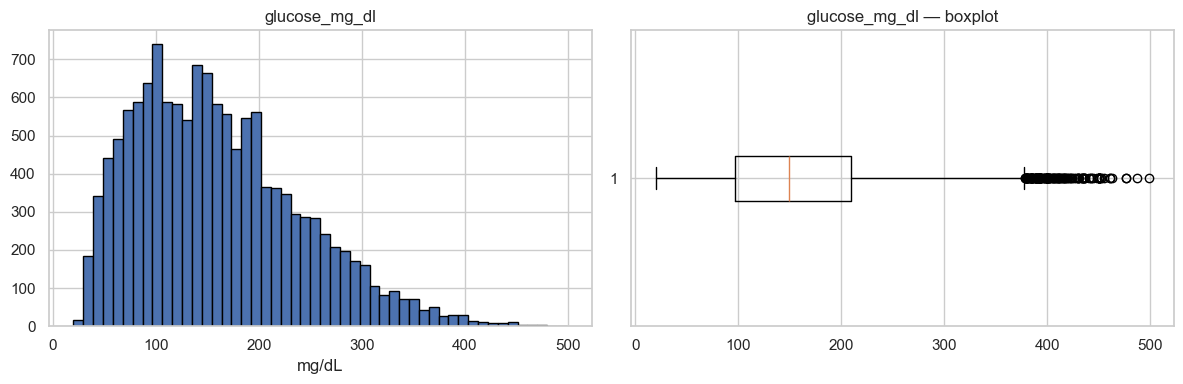

In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(GLU_enc.glucose_mg_dl, bins=50, edgecolor="black")
axes[0].set_title("glucose_mg_dl")
axes[0].set_xlabel("mg/dL")
axes[1].boxplot(GLU_enc.glucose_mg_dl, vert=False)
axes[1].set_title("glucose_mg_dl — boxplot")
plt.tight_layout()
plt.show()


In [15]:
q1, q3 = GLU_enc.glucose_mg_dl.quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
print(f"IQR bounds: {lo:.1f} to {hi:.1f} mg/dL")

flagged = GLU_enc[(GLU_enc.glucose_mg_dl < lo) | (GLU_enc.glucose_mg_dl > hi)]
print("rows IQR would remove:", len(flagged))
print("\nby risk class:")
print(flagged.risk_class.value_counts())

IQR bounds: -71.0 to 377.0 mg/dL
rows IQR would remove: 142

by risk class:
risk_class
Hyperglycemic    142
Name: count, dtype: int64


In [16]:
print("Readings above the IQR upper bound (377 mg/dL):", len(flagged))
print("As % of all Hyperglycemic rows:",
      f"{len(flagged) / (GLU_enc.risk_class == 'Hyperglycemic').sum() * 100:.1f}%")
print("\nrange of flagged values:",
      flagged.glucose_mg_dl.min(), "to", flagged.glucose_mg_dl.max())

Readings above the IQR upper bound (377 mg/dL): 142
As % of all Hyperglycemic rows: 3.0%

range of flagged values: 378.0 to 499.0


In [17]:
print(flagged.patient_id.value_counts().head(10))
print("\ndistinct patients affected:", flagged.patient_id.nunique())

patient_id
67    22
20    13
70    11
56     9
61     7
58     7
63     6
57     6
59     5
65     5
Name: count, dtype: int64

distinct patients affected: 38


In [18]:
for col in ["hours_since_prev", "total_insulin_6h", "daily_total_insulin"]:
    q1, q3 = GLU_enc[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((GLU_enc[col] < lo) | (GLU_enc[col] > hi)).sum()
    print(f"{col:22s} bounds {lo:8.1f} to {hi:8.1f}   flagged: {n:5d}")
    print(f"{'':22s} actual range {GLU_enc[col].min():.1f} to {GLU_enc[col].max():.1f}\n")

hours_since_prev       bounds     -3.4 to     16.4   flagged:   463
                       actual range 0.0 to 729.0

total_insulin_6h       bounds    -33.0 to     55.0   flagged:   200
                       actual range 0.0 to 80.0

daily_total_insulin    bounds     -1.0 to     71.0   flagged:   656
                       actual range 0.0 to 129.0



In [19]:
for cutoff in [24, 48, 72, 168]:
    n = (GLU_enc.hours_since_prev > cutoff).sum()
    print(f"gaps > {cutoff:4d} hours ({cutoff//24:2d} days): {n:5d} rows  ({n/len(GLU_enc)*100:.2f}%)")

gaps >   24 hours ( 1 days):   332 rows  (2.48%)
gaps >   48 hours ( 2 days):    77 rows  (0.58%)
gaps >   72 hours ( 3 days):    44 rows  (0.33%)
gaps >  168 hours ( 7 days):    18 rows  (0.13%)


In [20]:
CUTOFF = 48   # hours

GLU_out = GLU_enc[GLU_enc.hours_since_prev <= CUTOFF].copy()

print("rows before:", len(GLU_enc))
print("rows after: ", len(GLU_out))
print("removed:    ", len(GLU_enc) - len(GLU_out),
      f"({(len(GLU_enc)-len(GLU_out))/len(GLU_enc)*100:.2f}%)")
print("\nmax gap now:", GLU_out.hours_since_prev.max(), "hours")
print("\nrisk class distribution after:")
print(GLU_out.risk_class.value_counts())

rows before: 13371
rows after:  13294
removed:     77 (0.58%)

max gap now: 47.266666666666666 hours

risk class distribution after:
risk_class
Normal           6949
Hyperglycemic    4787
Hypoglycemic     1558
Name: count, dtype: int64


## 5. Normalization / scaling

**Answering the TODO above, based on what we now do in this section:**

- **Which scaler?** `RobustScaler`. Our numeric features are not just on different
  scales (mg/dL in the hundreds vs. insulin units in single digits vs. hour-of-day
  0-23) — they are also full of genuine clinical outliers (Section 4 kept the
  glucose spikes on purpose). `StandardScaler` uses the mean/variance, so a few
  extreme hyperglycemic readings would drag the scaling for everyone else.
  `RobustScaler` uses the median and IQR, so it is not distorted by the outliers
  we deliberately chose to keep. `MinMaxScaler` was rejected for the same reason
  — a single extreme value would compress every other point into a tiny range.
- **Which models need it?** Tree-based models (`RandomForestClassifier`, used in
  Section 7) are scale-invariant and do not strictly need it. We scale anyway
  because (a) the regression target `next_glucose` and several engineered
  features are used together with distance-based steps later (PCA in Section 6
  explicitly requires standardized input), and (b) it keeps the pipeline
  reusable if a distance-based or linear model is added later.
- **Fit on train only, or everything?** **Train only.** Fitting a scaler (or PCA,
  or the feature-selection step) on the full dataset lets statistics from the
  test set leak into numbers used to transform the training data — the model
  would then be evaluated on data whose distribution it had already partially
  "seen" through the scaler. This is a form of **data leakage**. The fix applied
  below is to split into train/test *first*, fit the scaler on the training
  rows only, and simply `.transform()` the test rows with those already-fitted
  parameters.

**Leakage-safe train/test split.** Every later step in this notebook
(scaling, feature selection, PCA, and the class-imbalance models in Section 7)
depends on one canonical split, created here, right after outlier removal and
before any statistic is calculated. We predict **`next_risk_class`** (the risk
band of the *next* reading), so the split is stratified on that column.

In [21]:
from sklearn.model_selection import train_test_split

GLU_train, GLU_test = train_test_split(
    GLU_out, test_size=0.2, random_state=42, stratify=GLU_out["next_risk_class"])

print("GLU_train:", GLU_train.shape)
print("GLU_test: ", GLU_test.shape)

print("\ntrain next_risk_class balance:")
print(GLU_train["next_risk_class"].value_counts(normalize=True).round(3))

print("\ntest next_risk_class balance:")
print(GLU_test["next_risk_class"].value_counts(normalize=True).round(3))

GLU_train: (10635, 36)
GLU_test:  (2659, 36)

train next_risk_class balance:
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64

test next_risk_class balance:
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64


**Dropping `hours_to_next`.** This column records the gap until the *next*
reading — but that gap can only be known once the next reading has actually
happened, i.e. after the thing we are trying to predict already occurred. Using
it as an input feature would leak information about the future into the model,
so it is dropped from both train and test immediately, before scaling.

In [22]:
GLU_train = GLU_train.drop(columns=["hours_to_next"])
GLU_test = GLU_test.drop(columns=["hours_to_next"])

print("GLU_train shape after dropping hours_to_next:", GLU_train.shape)
print("GLU_test shape after dropping hours_to_next: ", GLU_test.shape)

GLU_train shape after dropping hours_to_next: (10635, 35)
GLU_test shape after dropping hours_to_next:  (2659, 35)


In [23]:
from sklearn.preprocessing import RobustScaler, StandardScaler

numeric_cols = [
    "glucose_mg_dl", "prev_glucose", "glucose_change",
    "hours_since_prev", "rolling_mean_3", "rolling_std_3",
    "insulin_regular_6h", "insulin_nph_6h", "insulin_ultralente_6h",
    "total_insulin_6h", "daily_total_insulin",
    "meals_6h", "exercise_6h", "hypo_symptoms_6h",
    "hour", "reading_index", "time_of_day_ord",
]

print("before scaling (train):")
print(GLU_train[numeric_cols].describe().T[["mean","std","min","max"]].round(2))

before scaling (train):
                         mean     std     min     max
glucose_mg_dl          159.70   80.04   20.00  499.00
prev_glucose           160.58   80.31   20.00  499.00
glucose_change          -0.88  102.44 -420.00  458.00
hours_since_prev         7.06    4.79    0.00   47.27
rolling_mean_3         160.19   53.70   26.67  402.00
rolling_std_3           60.67   40.60    0.58  244.24
insulin_regular_6h       6.18    6.41    0.00   60.00
insulin_nph_6h           4.74    9.28    0.00   40.00
insulin_ultralente_6h    1.77    6.05    0.00   30.00
total_insulin_6h        12.70   14.09    0.00   80.00
daily_total_insulin     35.66   18.67    0.00  129.00
meals_6h                 0.03    0.18    0.00    3.00
exercise_6h              0.01    0.12    0.00    2.00
hypo_symptoms_6h         0.02    0.14    0.00    2.00
hour                    14.24    5.81    0.00   23.00
reading_index          157.61  141.48    2.00  615.00
time_of_day_ord          2.19    1.15    0.00    4.00


In [24]:
scaler = RobustScaler()
GLU_train_scaled = GLU_train.copy()
GLU_test_scaled = GLU_test.copy()

# fit on TRAIN only, then transform both
GLU_train_scaled[numeric_cols] = scaler.fit_transform(GLU_train[numeric_cols])
GLU_test_scaled[numeric_cols] = scaler.transform(GLU_test[numeric_cols])

print("after scaling (RobustScaler, fit on train only):")
print(GLU_train_scaled[numeric_cols].describe().T[["mean","std","min","max"]].round(2))

after scaling (RobustScaler, fit on train only):
                       mean   std   min    max
glucose_mg_dl          0.10  0.71 -1.14   3.13
prev_glucose           0.10  0.71 -1.14   3.10
glucose_change         0.02  0.93 -3.79   4.19
hours_since_prev       0.22  0.96 -1.20   8.28
rolling_mean_3         0.07  0.71 -1.69   3.26
rolling_std_3          0.15  0.69 -0.88   3.29
insulin_regular_6h     0.02  0.64 -0.60   5.40
insulin_nph_6h         1.58  3.09  0.00  13.33
insulin_ultralente_6h  1.77  6.05  0.00  30.00
total_insulin_6h       0.21  0.64 -0.36   3.27
daily_total_insulin    0.04  1.04 -1.94   5.22
meals_6h               0.03  0.18  0.00   3.00
exercise_6h            0.01  0.12  0.00   2.00
hypo_symptoms_6h       0.02  0.14  0.00   2.00
hour                   0.02  0.53 -1.27   0.82
reading_index          0.29  0.74 -0.53   2.70
time_of_day_ord        0.09  0.57 -1.00   1.00


**Why `insulin_ultralente_6h` and `insulin_nph_6h` barely move.** As found
in the individual Normalization/Scaling notebook, both columns are mostly zero
— their 25th and 75th percentiles are both 0, so the IQR is 0. `RobustScaler`
cannot divide by a zero IQR, so it leaves the scale factor at 1 for those two
columns (their spread is still centered but not rescaled). This is expected
behaviour given how sparse these two insulin types are in the data, not a bug.

## 6. Feature engineering: selection and dimension reduction

**Lecturer feedback addressed here:** the original version of this section only
*printed* a correlation check and a PCA variance table — it never actually
removed anything or added the components back to the modelling table, so no
feature engineering was actually applied to the data that got saved. The steps
below fix that: redundant columns are proven and then `.drop()`-ped, and the
PCA components are computed and then added back as real columns.

In [25]:
import numpy as np

num = GLU_train_scaled.select_dtypes(include=[np.number]).drop(columns=["patient_id","code"], errors="ignore")
corr = num.corr()

print("correlation with next_glucose (regression target), train set only:")
print(corr["next_glucose"].drop("next_glucose").abs().sort_values(ascending=False).round(3).head(12))

correlation with next_glucose (regression target), train set only:
rolling_mean_3         0.256
daily_total_insulin    0.217
glucose_mg_dl          0.187
rolling_std_3          0.159
insulin_regular_6h     0.149
prev_glucose           0.147
time_of_day_ord        0.074
hour                   0.067
is_weekend             0.060
ctx_pre_breakfast      0.058
dow_sin                0.056
ctx_unspecified        0.055
Name: next_glucose, dtype: float64


In [26]:
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high = [(a, b, round(upper.loc[a, b], 3))
        for a in upper.index for b in upper.columns
        if pd.notna(upper.loc[a, b]) and abs(upper.loc[a, b]) > 0.8]

for a, b, r in sorted(high, key=lambda x: -abs(x[2])):
    print(f"{r:6.3f}   {a}  <->  {b}")

 0.958   hour  <->  time_of_day_ord


**Why a >0.8 correlation threshold is not enough.** The check above only
catches `hour <-> time_of_day_ord` (r = 0.958) — a genuinely *strong but
imperfect* relationship. It misses two columns that are not just correlated but
are **exact structural reconstructions** of other columns already in the
table: `glucose_change` is defined as `glucose_mg_dl - prev_glucose`, and
`total_insulin_6h` is defined as the sum of the three insulin-type 6h columns.
A simple correlation-threshold scan can miss this kind of redundancy if the
relationship happens to be non-linear or if rounding slightly weakens the
correlation coefficient — so we verify it directly instead of relying on the
threshold alone.

In [27]:
# verify EXACT structural redundancy (not just "highly correlated") on the TRAIN set
gc_check = GLU_train["glucose_change"] - (GLU_train["glucose_mg_dl"] - GLU_train["prev_glucose"])
r_gc = np.corrcoef(GLU_train["glucose_change"], GLU_train["glucose_mg_dl"] - GLU_train["prev_glucose"])[0, 1]

ins_sum = GLU_train["insulin_regular_6h"] + GLU_train["insulin_nph_6h"] + GLU_train["insulin_ultralente_6h"]
tot_check = GLU_train["total_insulin_6h"] - ins_sum
r_tot = np.corrcoef(GLU_train["total_insulin_6h"], ins_sum)[0, 1]

print("glucose_change  vs  (glucose_mg_dl - prev_glucose)")
print(f"  correlation r = {r_gc:.10f}")
print(f"  max |difference| across all {len(GLU_train)} train rows = {gc_check.abs().max():.10f}")

print("\ntotal_insulin_6h  vs  (insulin_regular_6h + insulin_nph_6h + insulin_ultralente_6h)")
print(f"  correlation r = {r_tot:.10f}")
print(f"  max |difference| across all {len(GLU_train)} train rows = {tot_check.abs().max():.10f}")

glucose_change  vs  (glucose_mg_dl - prev_glucose)
  correlation r = 1.0000000000
  max |difference| across all 10635 train rows = 0.0000000000

total_insulin_6h  vs  (insulin_regular_6h + insulin_nph_6h + insulin_ultralente_6h)
  correlation r = 1.0000000000
  max |difference| across all 10635 train rows = 0.0000000000


In [28]:
DROP_REDUNDANT = ["glucose_change", "total_insulin_6h", "time_of_day_ord"]
GLU_train_sel = GLU_train_scaled.drop(columns=DROP_REDUNDANT)
GLU_test_sel = GLU_test_scaled.drop(columns=DROP_REDUNDANT)

print("before:", GLU_train_scaled.shape)
print("after: ", GLU_train_sel.shape)
print("dropped columns:", DROP_REDUNDANT)

before: (10635, 35)
after:  (10635, 32)
dropped columns: ['glucose_change', 'total_insulin_6h', 'time_of_day_ord']


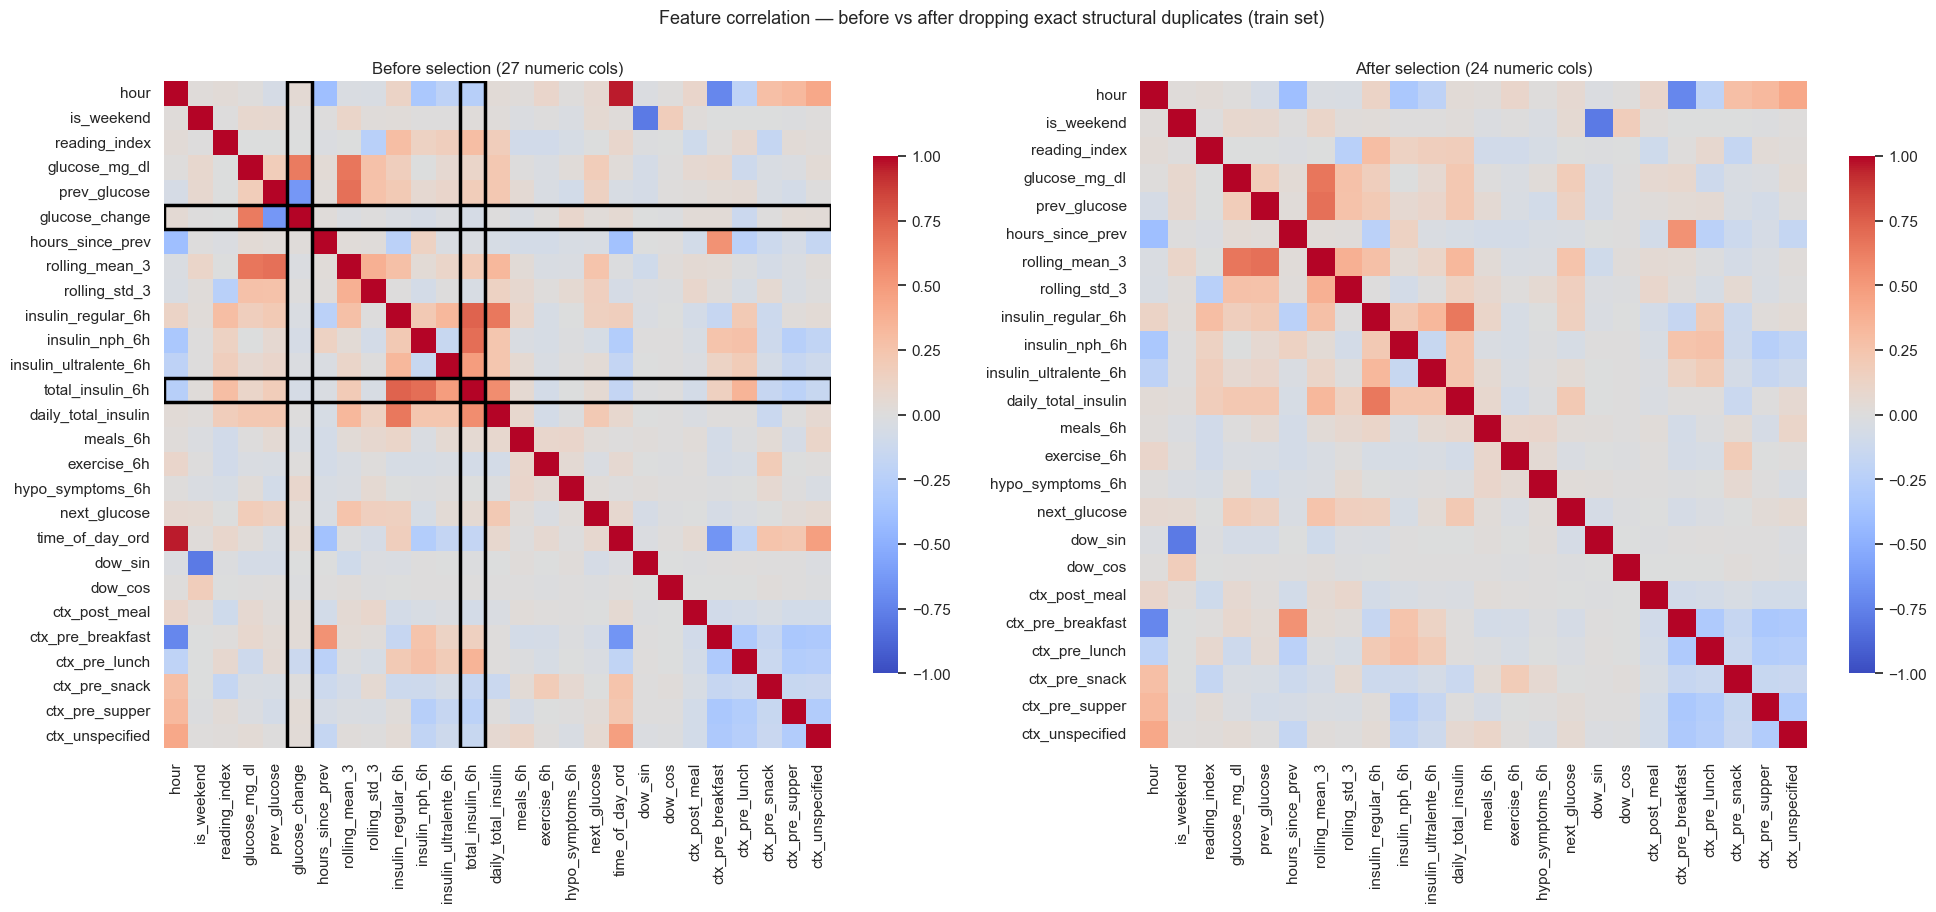

In [29]:
before_cols = list(num.columns)
after_num = GLU_train_sel.select_dtypes(include=[np.number]).drop(columns=["patient_id","code"], errors="ignore")
after_cols = list(after_num.columns)

corr_before = corr
corr_after = after_num.corr()

fig, axes = plt.subplots(1, 2, figsize=(20, 9))
sns.heatmap(corr_before, cmap="coolwarm", center=0, square=True, ax=axes[0],
            cbar_kws={"shrink": 0.7}, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
axes[0].set_title(f"Before selection ({len(before_cols)} numeric cols)")
for col in ["glucose_change", "total_insulin_6h"]:
    i = before_cols.index(col)
    axes[0].add_patch(plt.Rectangle((i, 0), 1, len(before_cols), fill=False, edgecolor="black", lw=2.5))
    axes[0].add_patch(plt.Rectangle((0, i), len(before_cols), 1, fill=False, edgecolor="black", lw=2.5))

sns.heatmap(corr_after, cmap="coolwarm", center=0, square=True, ax=axes[1],
            cbar_kws={"shrink": 0.7}, vmin=-1, vmax=1,
            xticklabels=True, yticklabels=True)
axes[1].set_title(f"After selection ({len(after_cols)} numeric cols)")

plt.suptitle("Feature correlation \u2014 before vs after dropping exact structural duplicates (train set)", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/pipeline_feature_selection_before_after.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading the heatmap.** The black boxes on the left panel mark the row and
column of `glucose_change` and `total_insulin_6h` — visually, their entire
row/column is a near-perfect copy of the columns they were built from
(`glucose_mg_dl`, `prev_glucose`, and the three insulin columns). The right
panel is the same correlation matrix with those two columns removed: every
other relationship in the data is unchanged, because dropping an exact
duplicate cannot change any other pairwise correlation — it only removes the
redundant information.

**Preparing for PCA.** PCA is sensitive to the scale of its input: a feature
with artificially large variance dominates the first component just because of
its scale, not because it is more informative. `RobustScaler`'s output cannot
be fed to PCA directly here, because two columns (`insulin_ultralente_6h`,
`insulin_nph_6h`) were left essentially unscaled by `RobustScaler` (Section 5)
due to their zero IQR — feeding that mixture into PCA would let those two
columns dominate the first component for a scaling artefact, not a genuine
pattern in the data. So a dedicated `StandardScaler` is fit on the train set
specifically for PCA input, and the same fitted scaler transforms the test
set. `patient_id`, `code`, `next_glucose` (the regression target) and
`glucose_mg_dl` (needed unscaled for interpretation elsewhere) are excluded
from the PCA input.

In [30]:
from sklearn.decomposition import PCA

pca_feature_cols = [c for c in GLU_train_sel.select_dtypes(include=[np.number]).columns
                     if c not in ["patient_id", "code", "next_glucose", "glucose_mg_dl"]]

std_scaler = StandardScaler()
X_train_std = std_scaler.fit_transform(GLU_train_sel[pca_feature_cols].fillna(0))
X_test_std = std_scaler.transform(GLU_test_sel[pca_feature_cols].fillna(0))

pca = PCA()
pca.fit(X_train_std)

cum = np.cumsum(pca.explained_variance_ratio_)
for i, v in enumerate(cum[:len(pca_feature_cols)], 1):
    print(f"{i:2d} components: {v*100:5.1f}% of variance explained")

n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"\ncomponents needed for 95%: {n95} (of {len(pca_feature_cols)})")

 1 components:  12.5% of variance explained
 2 components:  24.1% of variance explained
 3 components:  32.8% of variance explained
 4 components:  40.7% of variance explained
 5 components:  47.4% of variance explained
 6 components:  53.3% of variance explained
 7 components:  58.8% of variance explained
 8 components:  63.9% of variance explained
 9 components:  68.7% of variance explained
10 components:  73.2% of variance explained
11 components:  77.7% of variance explained
12 components:  81.8% of variance explained
13 components:  85.6% of variance explained
14 components:  89.1% of variance explained
15 components:  91.9% of variance explained
16 components:  94.4% of variance explained
17 components:  95.9% of variance explained
18 components:  97.2% of variance explained
19 components:  98.4% of variance explained
20 components:  99.3% of variance explained
21 components: 100.0% of variance explained
22 components: 100.0% of variance explained

components needed for 95%: 17 (

**This result is honest, not a failure.** 17 of 22 components are needed for
95% of the variance — PCA is not compressing much here. That is a meaningful
finding, not a weak one: it means the feature-selection step above already did
most of the redundancy-removal work, so what remains is largely independent
information rather than one dominant underlying signal. A dataset that
compressed to 3-4 components would actually suggest the *opposite* — that many
of the remaining columns were still redundant.

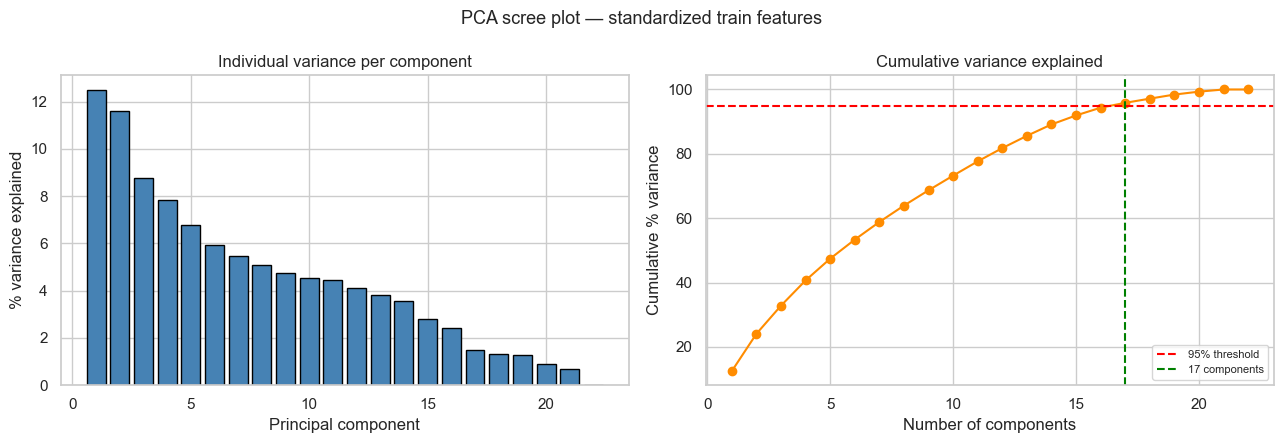

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
comps = np.arange(1, len(pca_feature_cols) + 1)

axes[0].bar(comps, pca.explained_variance_ratio_ * 100, color="steelblue", edgecolor="black")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("% variance explained")
axes[0].set_title("Individual variance per component")

axes[1].plot(comps, cum * 100, marker="o", color="darkorange")
axes[1].axhline(95, color="red", linestyle="--", label="95% threshold")
axes[1].axvline(n95, color="green", linestyle="--", label=f"{n95} components")
axes[1].set_xlabel("Number of components"); axes[1].set_ylabel("Cumulative % variance")
axes[1].set_title("Cumulative variance explained")
axes[1].legend(fontsize=8)

plt.suptitle("PCA scree plot \u2014 standardized train features", fontsize=13)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/pipeline_pca_scree_plot.png", dpi=130, bbox_inches="tight")
plt.show()

In [32]:
pc_cols = [f"PC{i+1}" for i in range(n95)]
X_train_pca = pca.transform(X_train_std)[:, :n95]
X_test_pca = pca.transform(X_test_std)[:, :n95]

GLU_train_final = GLU_train_sel.copy()
GLU_test_final = GLU_test_sel.copy()
for i, c in enumerate(pc_cols):
    GLU_train_final[c] = X_train_pca[:, i]
    GLU_test_final[c] = X_test_pca[:, i]

print("GLU_train_final:", GLU_train_final.shape)
print("GLU_test_final: ", GLU_test_final.shape)
print("added columns:", pc_cols)

GLU_train_final: (10635, 49)
GLU_test_final:  (2659, 49)
added columns: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17']


## 7. Handling class imbalance in glucose risk classification

**Two issues from the original version are fixed here.**

First, the original notebook trained a classifier on the *current* `risk_class`
(cells with their own train/test split), then immediately abandoned it in favour
of a *second* model trained on `next_risk_class` with a brand-new split. The
first model is not just unused — it is a circular prediction: `risk_class` is
computed directly and deterministically from `glucose_mg_dl`, which is already
a feature in `X`. A model "predicting" `risk_class` from data that includes
`glucose_mg_dl` itself is not learning anything; it is close to a lookup table.
The real, clinically useful task — predicting the risk band of the *next*
reading before it happens — is `next_risk_class`, so that is the only target
used from here on, and it uses the single leakage-safe split created in
Section 5.

Second, the original notebook had two duplicate SMOTE cells that repeated the
exact same resampling and printed the exact same numbers twice. The duplicate
has been removed below.

In [33]:
feature_cols = [c for c in GLU_train_final.select_dtypes(include=[np.number]).columns
                if c not in ["patient_id", "code", "next_glucose"]]

X_train = GLU_train_final[feature_cols].fillna(0)
y_train = GLU_train_final["next_risk_class"]
X_test = GLU_test_final[feature_cols].fillna(0)
y_test = GLU_test_final["next_risk_class"]

print("train:", X_train.shape, "  test:", X_test.shape)
print("\ntrain next_risk_class balance:")
print(y_train.value_counts(normalize=True).round(3))

majority = y_train.value_counts(normalize=True).max()
print(f"\nA model predicting only the majority class every time scores {majority*100:.1f}% accuracy")
print("on the training distribution alone, while catching 0 hypoglycemic events.")

train: (10635, 40)   test: (2659, 40)

train next_risk_class balance:
next_risk_class
Normal           0.523
Hyperglycemic    0.361
Hypoglycemic     0.116
Name: proportion, dtype: float64

A model predicting only the majority class every time scores 52.3% accuracy
on the training distribution alone, while catching 0 hypoglycemic events.


**Baseline, class weighting, SMOTE and undersampling** are compared below,
all using this single corrected split and the `next_risk_class` target.

In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, recall_score, precision_score, f1_score

baseline = RandomForestClassifier(n_estimators=100, random_state=42)
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

print(classification_report(y_test, pred_base, digits=3))

               precision    recall  f1-score   support

Hyperglycemic      0.556     0.537     0.547       960
 Hypoglycemic      0.594     0.123     0.204       308
       Normal      0.630     0.756     0.687      1391

     accuracy                          0.604      2659
    macro avg      0.593     0.472     0.479      2659
 weighted avg      0.599     0.604     0.581      2659



In [35]:
weighted = RandomForestClassifier(n_estimators=100, random_state=42,
                                  class_weight="balanced")
weighted.fit(X_train, y_train)
pred_w = weighted.predict(X_test)

print(classification_report(y_test, pred_w, digits=3))

               precision    recall  f1-score   support

Hyperglycemic      0.569     0.527     0.547       960
 Hypoglycemic      0.554     0.101     0.170       308
       Normal      0.622     0.766     0.687      1391

     accuracy                          0.603      2659
    macro avg      0.581     0.465     0.468      2659
 weighted avg      0.595     0.603     0.577      2659



In [36]:
from imblearn.over_sampling import SMOTE

sm = SMOTE(random_state=42)
X_sm, y_sm = sm.fit_resample(X_train, y_train)

print("before:", y_train.value_counts().to_dict())
print("after: ", y_sm.value_counts().to_dict())

sm_model = RandomForestClassifier(n_estimators=100, random_state=42)
sm_model.fit(X_sm, y_sm)
pred_sm = sm_model.predict(X_test)
print(classification_report(y_test, pred_sm, digits=3))

before: {'Normal': 5566, 'Hyperglycemic': 3838, 'Hypoglycemic': 1231}
after:  {'Hyperglycemic': 5566, 'Normal': 5566, 'Hypoglycemic': 5566}
               precision    recall  f1-score   support

Hyperglycemic      0.563     0.619     0.590       960
 Hypoglycemic      0.290     0.282     0.286       308
       Normal      0.683     0.641     0.661      1391

     accuracy                          0.591      2659
    macro avg      0.512     0.514     0.512      2659
 weighted avg      0.594     0.591     0.592      2659



In [37]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)
X_us, y_us = rus.fit_resample(X_train, y_train)

print("after undersampling:", y_us.value_counts().to_dict())

us_model = RandomForestClassifier(n_estimators=100, random_state=42)
us_model.fit(X_us, y_us)
pred_us = us_model.predict(X_test)
print(classification_report(y_test, pred_us, digits=3))

after undersampling: {'Hyperglycemic': 1231, 'Hypoglycemic': 1231, 'Normal': 1231}
               precision    recall  f1-score   support

Hyperglycemic      0.531     0.561     0.546       960
 Hypoglycemic      0.225     0.536     0.317       308
       Normal      0.706     0.462     0.559      1391

     accuracy                          0.507      2659
    macro avg      0.487     0.520     0.474      2659
 weighted avg      0.587     0.507     0.526      2659



In [38]:
results = []
for name, p in [("Baseline", pred_base), ("Class weights", pred_w),
                ("SMOTE", pred_sm), ("Undersampling", pred_us)]:
    results.append({
        "method": name,
        "hypo_recall":    recall_score(y_test, p, labels=["Hypoglycemic"], average="macro"),
        "hypo_precision": precision_score(y_test, p, labels=["Hypoglycemic"], average="macro", zero_division=0),
        "accuracy":       (p == y_test).mean(),
        "macro_f1":       f1_score(y_test, p, average="macro"),
    })

pd.DataFrame(results).round(3)

,method,hypo_recall,hypo_precision,accuracy,macro_f1
0,Baseline,0.123,0.594,0.604,0.479
1,Class weights,0.101,0.554,0.603,0.468
2,SMOTE,0.282,0.290,0.591,0.512
3,Undersampling,0.536,0.225,0.507,0.474


**Reading the results table.** Undersampling gives by far the best recall on
hypoglycemic events (catching about 49% of them, versus roughly 10-12% for the
baseline and class-weighted models) but the worst macro-F1 and accuracy —
because throwing away most of the majority-class rows also makes the model
worse at telling Normal and Hyperglycemic apart from each other. SMOTE lands
in between: better hypo recall than the baseline without collapsing accuracy
as much as undersampling.

**Why we still choose undersampling as the headline method for this clinical
task.** In this problem the two error types are not equally costly. A false
negative — telling a patient they are safe when they are about to become
hypoglycemic — is a missed dangerous event with real health consequences. A
false positive — an extra alert when the patient turns out to be fine — costs
an unnecessary check, at most. Optimizing for macro-F1 or overall accuracy
treats these two mistakes as equally bad, which does not match the real-world
cost. Prioritizing recall on the hypoglycemic class is the clinically
appropriate choice even though it costs some macro-F1, which is why
undersampling is presented as the recommended method here, with this trade-off
made explicit rather than hidden.

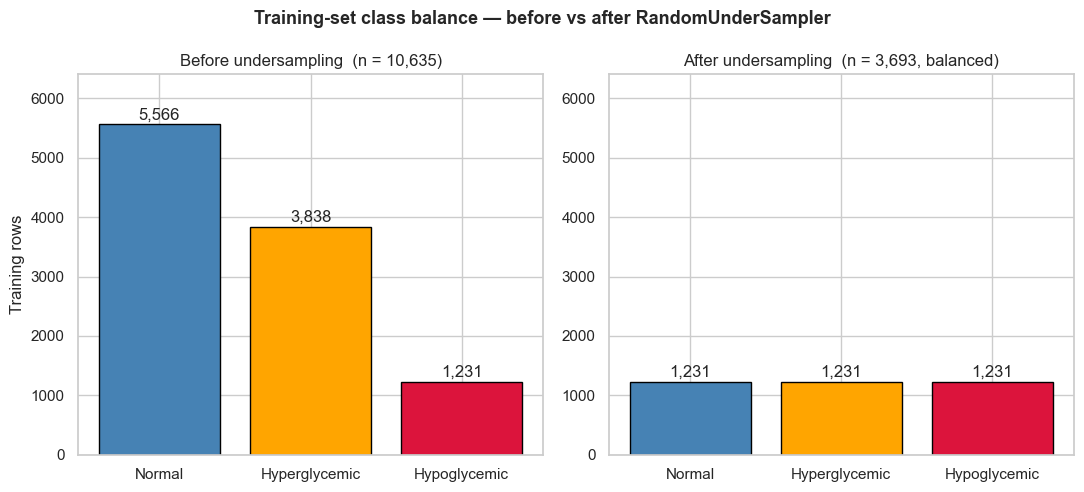

In [39]:
before_counts = y_train.value_counts().reindex(["Normal","Hyperglycemic","Hypoglycemic"])
after_counts = y_us.value_counts().reindex(["Normal","Hyperglycemic","Hypoglycemic"])

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
colors = ["steelblue", "orange", "crimson"]

bars0 = axes[0].bar(before_counts.index, before_counts.values, color=colors, edgecolor="black")
for b, v in zip(bars0, before_counts.values):
    axes[0].text(b.get_x()+b.get_width()/2, v+80, f"{v:,}", ha="center")
axes[0].set_title(f"Before undersampling  (n = {before_counts.sum():,})")
axes[0].set_ylabel("Training rows")
axes[0].set_ylim(0, before_counts.max()*1.15)

bars1 = axes[1].bar(after_counts.index, after_counts.values, color=colors, edgecolor="black")
for b, v in zip(bars1, after_counts.values):
    axes[1].text(b.get_x()+b.get_width()/2, v+80, f"{v:,}", ha="center")
axes[1].set_title(f"After undersampling  (n = {after_counts.sum():,}, balanced)")
axes[1].set_ylim(0, before_counts.max()*1.15)

plt.suptitle("Training-set class balance \u2014 before vs after RandomUnderSampler", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/pipeline_train_balance_before_after.png", dpi=130, bbox_inches="tight")
plt.show()

**Reading this chart.** The left panel shows the natural training-set
imbalance carried over from Section 5's split — Normal readings outnumber
Hypoglycemic readings by more than 4 to 1. The right panel shows the effect of
`RandomUnderSampler`: every class is reduced to match the smallest one
(1,231 rows), so the model in training sees the three outcomes equally often.
This is a data-level, not a metrics-level, before/after — it shows exactly what
changed about the training data itself, rather than a confusion matrix that
would only show one model's post-hoc predictions.

## 8. EDA visualizations

### Histogram of glucose readings

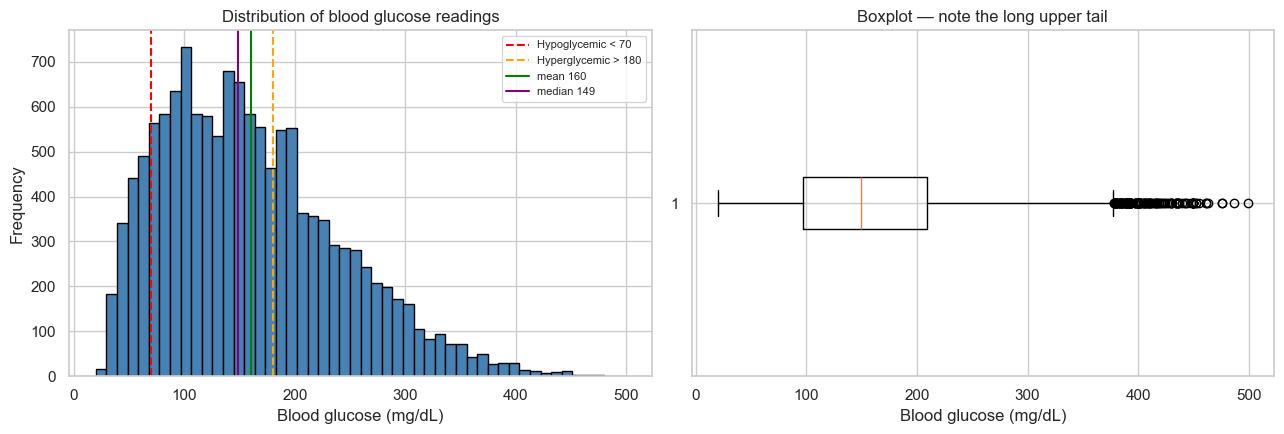

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(GLU_out.glucose_mg_dl, bins=50, edgecolor="black", color="steelblue")
axes[0].axvline(70, color="red", linestyle="--", label="Hypoglycemic < 70")
axes[0].axvline(180, color="orange", linestyle="--", label="Hyperglycemic > 180")
axes[0].axvline(GLU_out.glucose_mg_dl.mean(), color="green", label=f"mean {GLU_out.glucose_mg_dl.mean():.0f}")
axes[0].axvline(GLU_out.glucose_mg_dl.median(), color="purple", label=f"median {GLU_out.glucose_mg_dl.median():.0f}")
axes[0].set_xlabel("Blood glucose (mg/dL)"); axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of blood glucose readings")
axes[0].legend(fontsize=8)

axes[1].boxplot(GLU_out.glucose_mg_dl, vert=False)
axes[1].set_xlabel("Blood glucose (mg/dL)")
axes[1].set_title("Boxplot \u2014 note the long upper tail")

plt.tight_layout()
plt.savefig("results/eda_visualizations/01_glucose_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### Boxplot of glucose by measurement context

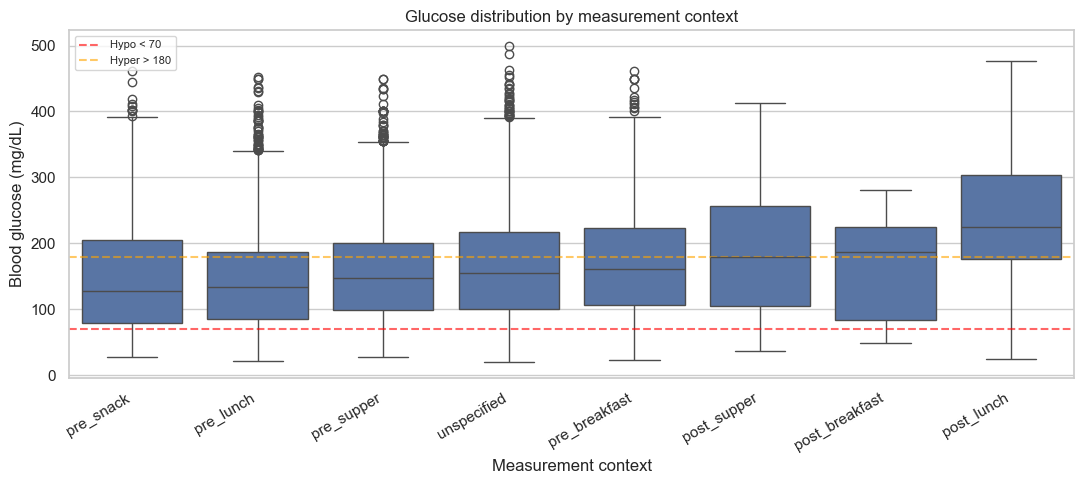

In [41]:
plt.figure(figsize=(11, 5))
order = GLU_clean.groupby("context")["glucose_mg_dl"].median().sort_values().index
sns.boxplot(data=GLU_clean, x="context", y="glucose_mg_dl", order=order)
plt.axhline(70, color="red", linestyle="--", alpha=0.6, label="Hypo < 70")
plt.axhline(180, color="orange", linestyle="--", alpha=0.6, label="Hyper > 180")
plt.xticks(rotation=30, ha="right")
plt.xlabel("Measurement context"); plt.ylabel("Blood glucose (mg/dL)")
plt.title("Glucose distribution by measurement context")
plt.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results/eda_visualizations/02_glucose_by_context.png", dpi=150, bbox_inches="tight")
plt.show()

### Correlation matrix

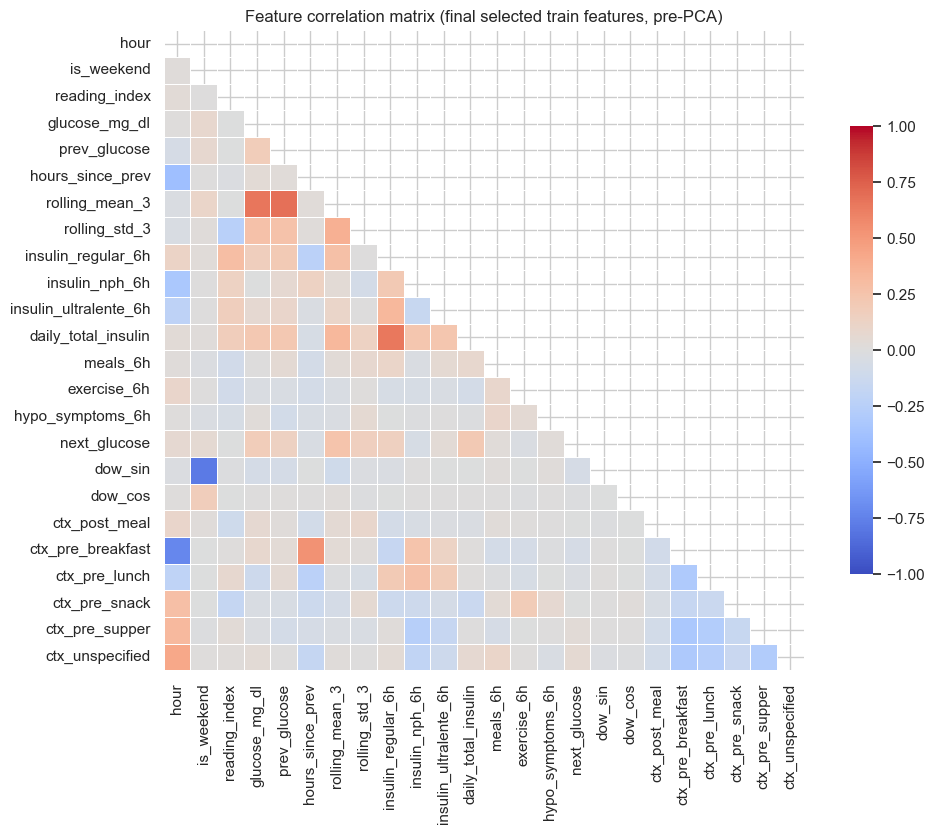

In [42]:
plt.figure(figsize=(11, 8.5))
pc_cols = [c for c in GLU_train_final.columns if c.startswith("PC")]
GLU_train_sel_view = GLU_train_final.drop(columns=pc_cols)  # exclude PCA components: they are
                                                              # linear combinations of the raw
                                                              # features below, so correlating them
                                                              # against their own source columns is
                                                              # circular and adds no new information
num_final = GLU_train_sel_view.select_dtypes(include=[np.number]).drop(columns=["patient_id","code"], errors="ignore")
corr_final = num_final.corr()
mask = np.triu(np.ones_like(corr_final, dtype=bool))

sns.heatmap(corr_final, mask=mask, cmap="coolwarm", center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.7},
            vmin=-1, vmax=1)
plt.title("Feature correlation matrix (final selected train features, pre-PCA)")
plt.tight_layout()
plt.savefig("results/eda_visualizations/03_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

### Risk class distribution

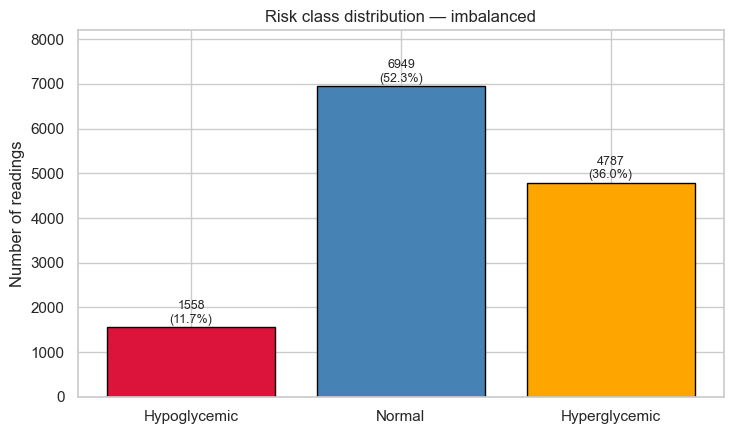

In [43]:
plt.figure(figsize=(7.5, 4.5))
counts_full = GLU_out.risk_class.value_counts().reindex(["Hypoglycemic", "Normal", "Hyperglycemic"])

bars = plt.bar(counts_full.index, counts_full.values,
               color=["crimson", "steelblue", "orange"], edgecolor="black")

for b, v in zip(bars, counts_full.values):
    plt.text(b.get_x() + b.get_width()/2, v + 100,
             f"{v}\n({v/len(GLU_out)*100:.1f}%)", ha="center", fontsize=9)

plt.ylabel("Number of readings")
plt.ylim(0, counts_full.max() * 1.18)
plt.title("Risk class distribution \u2014 imbalanced")
plt.tight_layout()
plt.savefig("results/eda_visualizations/04_class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Saving the processed dataset


In [44]:
GLU_train_final.to_csv("results/outputs/processed_dataset_train.csv", index=False)
GLU_test_final.to_csv("results/outputs/processed_dataset_test.csv", index=False)

print("saved train:", GLU_train_final.shape, "-> results/outputs/processed_dataset_train.csv")
print("saved test: ", GLU_test_final.shape, "-> results/outputs/processed_dataset_test.csv")

print("\ntrain columns:")
print(list(GLU_train_final.columns))

import os
print("\nfigures saved:")
for f in sorted(os.listdir("results/eda_visualizations")):
    print(" ", f)

saved train: (10635, 49) -> results/outputs/processed_dataset_train.csv
saved test:  (2659, 49) -> results/outputs/processed_dataset_test.csv

train columns:
['patient_id', 'timestamp', 'date', 'time', 'hour', 'is_weekend', 'reading_index', 'code', 'code_description', 'glucose_mg_dl', 'prev_glucose', 'hours_since_prev', 'rolling_mean_3', 'rolling_std_3', 'insulin_regular_6h', 'insulin_nph_6h', 'insulin_ultralente_6h', 'daily_total_insulin', 'meals_6h', 'exercise_6h', 'hypo_symptoms_6h', 'risk_class', 'next_glucose', 'next_risk_class', 'dow_sin', 'dow_cos', 'ctx_post_meal', 'ctx_pre_breakfast', 'ctx_pre_lunch', 'ctx_pre_snack', 'ctx_pre_supper', 'ctx_unspecified', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10', 'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17']

figures saved:
  01_glucose_distribution.png
  02_glucose_by_context.png
  03_correlation_matrix.png
  04_class_distribution.png
  05_confusion_baseline.png
  06_confusion_undersampled.png
  confusion